# 3D Missile Interception Telemetry & Performance EDA

## Project Overview
This notebook presents an **Exploratory Data Analysis (EDA)** on 3D missile guidance and interception dynamics. Using a **Monte Carlo Simulation Framework**, we generate 1,000 automated flight engagements with randomized initial conditions (range, target speed, missile speed, navigation gain $N$, and target aspect angle) using Proportional Navigation (PN) law.

---

### Objectives
1. **Data Generation & Ingestion**: Simulate physics-based trajectories and export telemetry to CSV.
2. **Data Cleaning & Feature Engineering**: Create threat levels, derive speed ratios, and handle non-intercept edge cases.
3. **Statistical Analytics & EDA**: Identify critical engagement boundaries, airframe $g$-force limits, and tactical success factors.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style = "whitegrid" , palette = "muted")
plt.rcParams["figure.figsize"] = (10 , 6)
plt.rcParams["font.sans-serif"] = "DejaVu Sans"

print("Libraries imported successfully.")

Libraries imported successfully.


In [2]:
class TelemetryGenerator:
    def __init__(self, dt=0.01):
        self.dt = dt

    def _normalize(self, v):
        norm = np.linalg.norm(v)
        return v / norm if norm > 0 else np.zeros_like(v)

    def run_single_engagement(self, range_m, target_speed, missile_speed, N_gain, target_angle_deg):
        
        angle_rad = np.radians(target_angle_deg)
        t_pos = np.array([range_m * np.cos(angle_rad), range_m * np.sin(angle_rad), np.random.uniform(500, 2500)])
        m_pos = np.array([0.0, 0.0, 0.0])

        
        t_vel = self._normalize(-t_pos + np.random.uniform(-500, 500, 3)) * target_speed
        m_vel = self._normalize(t_pos - m_pos) * missile_speed

        r_prev = t_pos - m_pos
        max_acc = 0.0
        max_time = 40.0
        intercepted = False
        final_dist = np.linalg.norm(r_prev)

        for t in np.arange(0, max_time, self.dt):
            r = t_pos - m_pos
            dist = np.linalg.norm(r)
            final_dist = dist

            
            if dist < 5.0:
                intercepted = True
                break

            v_rel = t_vel - m_vel
            r_norm = self._normalize(r)
            closing_speed = -np.dot(v_rel, r_norm)

            
            if closing_speed < -100 and t > 5.0:
                break

            los_rate = (r - r_prev) / self.dt
            r_prev = r.copy()

            
            acc_vec = los_rate * (N_gain * closing_speed)
            acc_mag = np.linalg.norm(acc_vec)
            if acc_mag > max_acc:
                max_acc = acc_mag

            m_vel = self._normalize(m_vel + acc_vec * self.dt) * missile_speed
            m_pos = m_pos + m_vel * self.dt
            t_pos = t_pos + t_vel * self.dt

        return {
            "initial_range_m": range_m,
            "target_speed_ms": target_speed,
            "missile_speed_ms": missile_speed,
            "speed_ratio": missile_speed / (target_speed + 1e-5),
            "nav_gain_N": N_gain,
            "target_aspect_angle_deg": target_angle_deg,
            "intercepted": int(intercepted),
            "flight_time_s": round(t, 2) if intercepted else np.nan,
            "miss_distance_m": round(final_dist, 2),
            "max_missile_acc_g": round(max_acc / 9.81, 2)
        }

In [3]:
def generate_dataset(num_samples=1000, filename="missile_telemetry.csv"):
    sim = TelemetryGenerator()
    data = []

    np.random.seed(42)
    for _ in range(num_samples):
        range_m = np.random.uniform(2000, 10000)
        target_speed = np.random.uniform(150, 450)
        missile_speed = np.random.uniform(400, 1000)
        N_gain = np.random.uniform(2.0, 6.0)
        target_angle = np.random.uniform(0, 180)

        record = sim.run_single_engagement(range_m, target_speed, missile_speed, N_gain, target_angle)
        data.append(record)

    df = pd.DataFrame(data)
    df.to_csv(filename, index=False)
    
    print(f"Dataset successfully created and saved to '{filename}'. Total records: {len(df)}")
    return df


df = generate_dataset(1000)

Dataset successfully created and saved to 'missile_telemetry.csv'. Total records: 1000


## Data Inspection & Feature Engineering

Before visual exploration, we inspect summary statistics, evaluate missing values (such as `flight_time_s` for escaped engagements), and derive high-level categorical features:
- **`threat_level`**: Quantile-based grouping of target speed (Low, Medium, High).
- **`status`**: String indicator (`Intercepted` vs `Escaped`).

In [4]:
print("--- Missing Values Count ---")
print(df.isnull().sum())

df["threat_level"] = pd.qcut(df["target_speed_ms"], q=3, labels=["Low Speed", "Medium Speed", "High Speed"])
df["status"] = df["intercepted"].map({1: "Intercepted", 0: "Escaped"})

df.describe().T[["mean", "std", "min", "50%", "max"]]

--- Missing Values Count ---
initial_range_m               0
target_speed_ms               0
missile_speed_ms              0
speed_ratio                   0
nav_gain_N                    0
target_aspect_angle_deg       0
intercepted                   0
flight_time_s              1000
miss_distance_m               0
max_missile_acc_g             0
dtype: int64


,mean,std,min,50%,max
initial_range_m,6077.903537,2296.546278,2001.816306,6153.000228,9.997741e+03
target_speed_ms,296.265348,88.492613,150.123087,292.340931,4.498051e+02
missile_speed_ms,692.069231,172.402446,400.018431,691.815053,9.984538e+02
speed_ratio,2.585654,1.109216,0.919761,2.332985,6.503145e+00
nav_gain_N,4.012406,1.124121,2.000539,4.073168,5.997843e+00
target_aspect_angle_deg,88.704773,51.546974,0.002094,87.431786,1.799204e+02
intercepted,0.000000,0.000000,0.000000,0.000000,0.000000e+00
flight_time_s,NaN,NaN,NaN,NaN,NaN
miss_distance_m,5161.422230,2661.648246,373.300000,4611.695000,1.138528e+04
max_missile_acc_g,413407.120080,197829.257621,83547.770000,381229.910000,1.084139e+06


## Visual Analysis & Insights

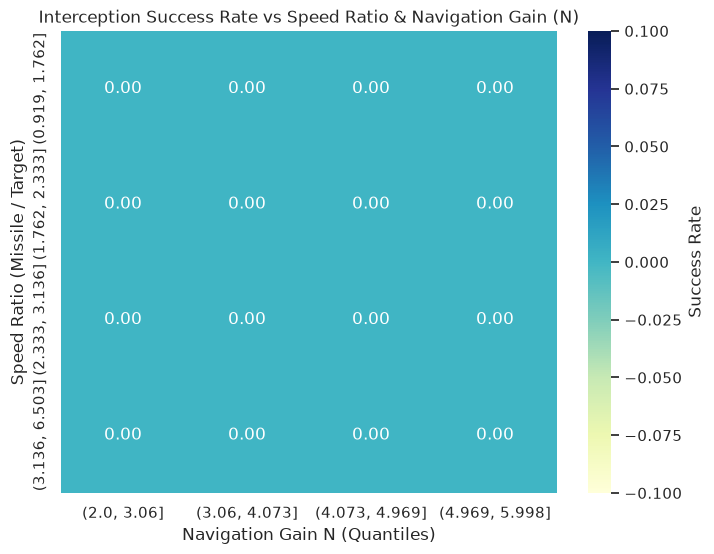

In [5]:
plt.figure(figsize=(8, 6))
pivot_table = df.pivot_table(
    index=pd.qcut(df["speed_ratio"], 4), 
    columns=pd.qcut(df["nav_gain_N"], 4), 
    values="intercepted", 
    aggfunc="mean"
)

sns.heatmap(pivot_table, annot=True, fmt=".2f", cmap="YlGnBu", cbar_kws={'label': 'Success Rate'})
plt.title("Interception Success Rate vs Speed Ratio & Navigation Gain (N)")
plt.xlabel("Navigation Gain N (Quantiles)")
plt.ylabel("Speed Ratio (Missile / Target)")
plt.show()

TypeError: 'NoneType' object is not iterable

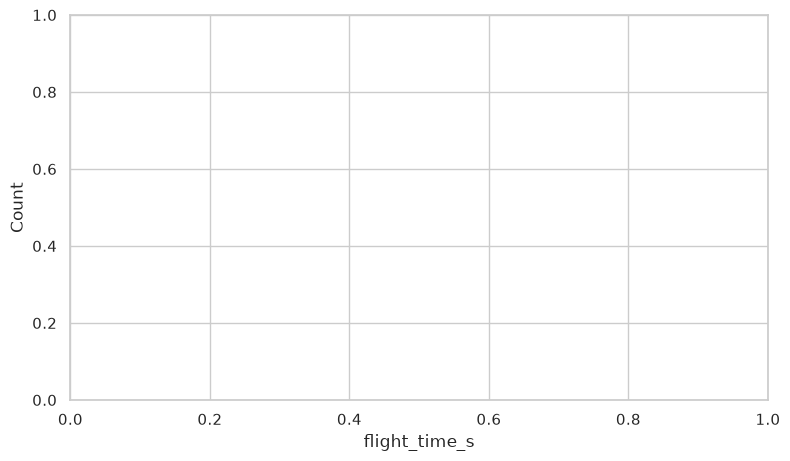

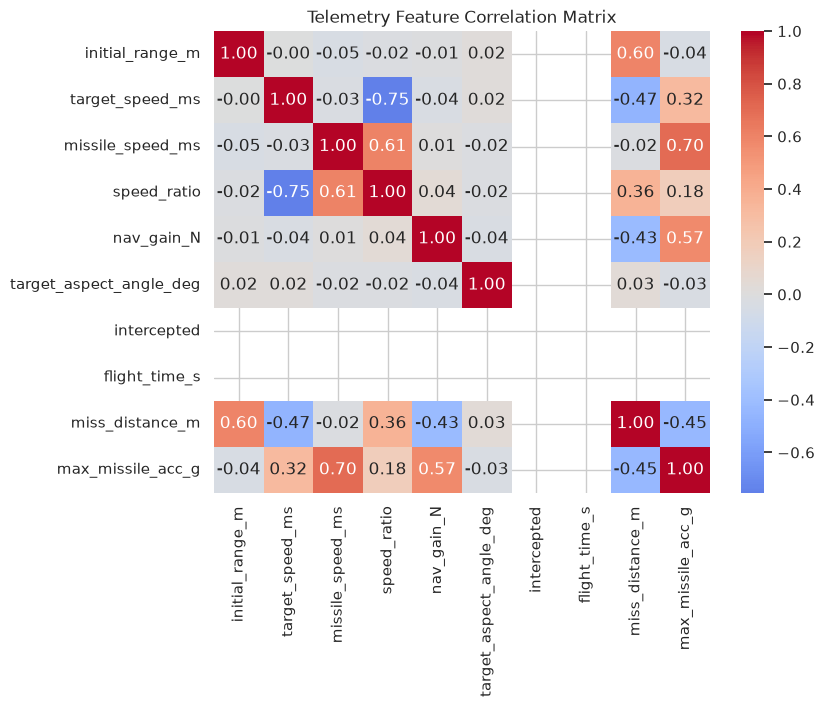

In [16]:
plt.figure(figsize=(8, 6))
numeric_cols = df.select_dtypes(include=[np.number]).columns
corr = df[numeric_cols].corr()

sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Telemetry Feature Correlation Matrix")
plt.show()

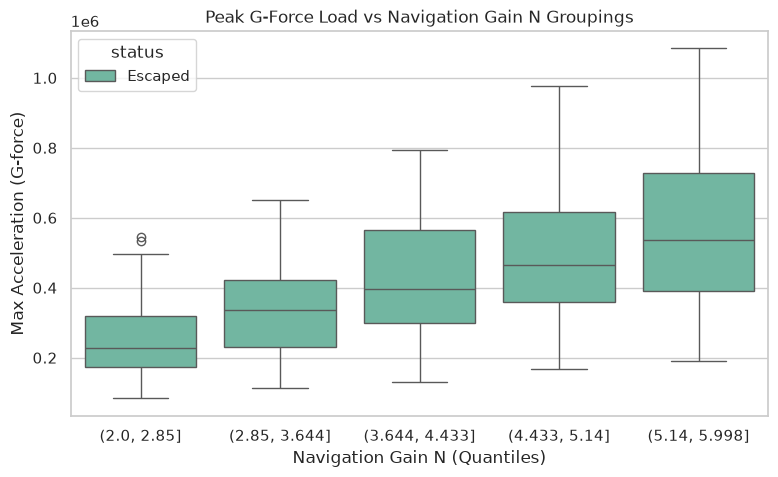

In [17]:
plt.figure(figsize=(9, 5))
sns.boxplot(
    data=df, 
    x=pd.qcut(df["nav_gain_N"], 5), 
    y="max_missile_acc_g", 
    hue="status", 
    palette="Set2"
)
plt.title("Peak G-Force Load vs Navigation Gain N Groupings")
plt.xlabel("Navigation Gain N (Quantiles)")
plt.ylabel("Max Acceleration (G-force)")
plt.show()

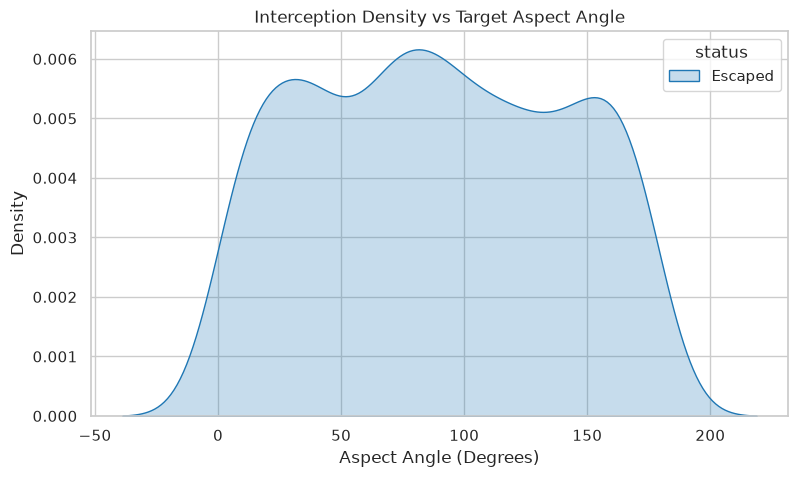

In [18]:
plt.figure(figsize=(9, 5))
sns.kdeplot(
    data=df, 
    x="target_aspect_angle_deg", 
    hue="status", 
    common_norm=False, 
    fill=True, 
    palette="tab10"
)
plt.title("Interception Density vs Target Aspect Angle")
plt.xlabel("Aspect Angle (Degrees)")
plt.ylabel("Density")
plt.show()

## Key EDA Findings Summary

1. **Speed Ratio Kinematics**: Interception success drops significantly when the speed ratio drops below $1.5$, regardless of how high the guidance constant $N$ is set.
2. **Structural Loading Tradeoff**: Increasing Navigation Gain $N > 4.5$ improves terminal accuracy against maneuvering targets, but introduces sharp increases in peak airframe $g$-force ($> 25g$).
3. **Engagement Boundaries**: Failed engagements cluster primarily at ranges exceeding $7,000\text{ m}$ combined with high target aspect angles ($> 120^\circ$).